# 01 — Isolation Forest (Unsupervised Anomaly Detector)

First member of the ML ensemble layer (Isolation Forest + Autoencoder + Random Forest,
combined later in the Fusion Layer — not built here). This notebook builds and evaluates
**only** the Isolation Forest model, on CICIDS-2017. UNSW-NB15 is left for the later
cross-dataset evaluation stage, after all three ensemble members exist.

Isolation Forest is unsupervised: `Label` is never used as a model input, only to evaluate
the model's output afterwards.

## 1. Setup

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FEATURES_DIR = ROOT / "data" / "features"
LOAO_DIR = ROOT / "data" / "processed" / "loao"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

print("ROOT:", ROOT)

ROOT: E:\thesis


In [3]:
CONTAMINATION = "auto"
N_ESTIMATORS = 100
RANDOM_STATE = 42

In [4]:
train_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_train.parquet")
val_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_val.parquet")

print("train_df shape:", train_df.shape)
print("val_df shape:  ", val_df.shape)

train_df shape: (1780264, 89)
val_df shape:   (504160, 89)


## 2. Feature selection

Exclude the label and MITRE reference columns; keep every remaining numeric column
as model input (matches how `feature_extractor.py` defines network features — no
hand-picked subset).

**Leakage fix (applied after the first run of this notebook):** `technique_id_encoded`,
`tactic_encoded`, `mapping_confidence_encoded`, and `is_known_technique` are also excluded
now. These 4 columns come from `label_builder.py`'s static MITRE lookup table, joined onto
each row keyed by its *true* `Label`/`attack_cat` — a check on the labeled data confirms
each one is an exact deterministic function of `Label` (1 unique value per `Label` group,
no exceptions). They are not observable at detection time; including them let all three
model inputs re-derive the ground truth instead of learning from real traffic features,
inflating every metric. They are reserved for the downstream RAG/LLM explanation layer,
which runs *after* a detection decision already exists and legitimately needs the MITRE
context to write the explanation — not for any of the three ensemble detection models
(Isolation Forest, Autoencoder, Random Forest).

In [5]:
NON_FEATURE_COLS = [
    "Label", "attack_cat", "technique_id", "technique_name", "tactic", "mapping_confidence",
    "technique_id_encoded", "tactic_encoded", "mapping_confidence_encoded", "is_known_technique",
]

def select_feature_columns(df, non_feature_cols=NON_FEATURE_COLS):
    return [
        c for c in df.columns
        if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])
    ]

feature_cols = select_feature_columns(train_df)
assert feature_cols == select_feature_columns(val_df), "train/val feature columns must match exactly"

print(f"Model input feature count: {len(feature_cols)}")
print("Feature columns used:")
for c in feature_cols:
    print(" -", c)

Model input feature count: 80
Feature columns used:
 - Destination Port
 - Flow Duration
 - Total Fwd Packets
 - Total Backward Packets
 - Total Length of Fwd Packets
 - Total Length of Bwd Packets
 - Fwd Packet Length Max
 - Fwd Packet Length Min
 - Fwd Packet Length Mean
 - Fwd Packet Length Std
 - Bwd Packet Length Max
 - Bwd Packet Length Min
 - Bwd Packet Length Mean
 - Bwd Packet Length Std
 - Flow Bytes/s
 - Flow Packets/s
 - Flow IAT Mean
 - Flow IAT Std
 - Flow IAT Max
 - Flow IAT Min
 - Fwd IAT Total
 - Fwd IAT Mean
 - Fwd IAT Std
 - Fwd IAT Max
 - Fwd IAT Min
 - Bwd IAT Total
 - Bwd IAT Mean
 - Bwd IAT Std
 - Bwd IAT Max
 - Bwd IAT Min
 - Fwd PSH Flags
 - Bwd PSH Flags
 - Fwd URG Flags
 - Bwd URG Flags
 - Fwd Header Length
 - Bwd Header Length
 - Fwd Packets/s
 - Bwd Packets/s
 - Min Packet Length
 - Max Packet Length
 - Packet Length Mean
 - Packet Length Std
 - Packet Length Variance
 - FIN Flag Count
 - SYN Flag Count
 - RST Flag Count
 - PSH Flag Count
 - ACK Flag Count


## 3. Train Isolation Forest

Trained on the **full mixed train set** (BENIGN + all attack types), not a BENIGN-only
subset — that BENIGN-only training regime is the Autoencoder's job later in the ensemble.
Isolation Forest is meant to isolate rare/short-path points regardless of label, so mixing
in the (comparatively rare) attack rows is the standard way to use it.

In [6]:
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)

iso_forest_main = IsolationForest(
    n_estimators=N_ESTIMATORS,
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
iso_forest_main.fit(X_train)
print("Fitted IsolationForest on", X_train.shape[0], "rows,", X_train.shape[1], "features.")

Fitted IsolationForest on 1780264 rows, 80 features.


## 4. Score the validation set

sklearn convention: `score_samples` is **higher = more normal** (negative scores lean
outlier), and `predict` returns **-1 = anomaly, 1 = normal**. Both are flipped/remapped
below to the project-wide convention **1 = anomaly/attack, 0 = normal**, and
**higher anomaly_score = more anomalous** — this remapping is the single most common
source of bugs when scores from different models are combined later in the Fusion Layer,
so it happens once, explicitly, here.

In [7]:
X_val = val_df[feature_cols].to_numpy(dtype=np.float64)

raw_normality_score = iso_forest_main.score_samples(X_val)
anomaly_score = -raw_normality_score

raw_pred = iso_forest_main.predict(X_val)
prediction = (raw_pred == -1).astype(int)

print("anomaly_score range:", anomaly_score.min(), "to", anomaly_score.max())
print("prediction value counts:", pd.Series(prediction).value_counts().to_dict())

anomaly_score range: 0.3288191871364081 to 0.7289402317208842
prediction value counts: {0: 452633, 1: 51527}


## 5. Evaluate against ground truth

`Label` is only used here, for evaluation — never as a model input.

In [8]:
y_true = (val_df["Label"] != "BENIGN").astype(int).to_numpy()

precision = precision_score(y_true, prediction)
recall = recall_score(y_true, prediction)
f1 = f1_score(y_true, prediction)
auc_roc = roc_auc_score(y_true, anomaly_score)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1        : {f1:.4f}")
print(f"AUC-ROC   : {auc_roc:.4f}")

Precision : 0.4881
Recall    : 0.2953
F1        : 0.3680
AUC-ROC   : 0.7286


### Leakage check: before vs after the Section 2 fix

`PRE_FIX_METRICS` below are hardcoded, not recomputed — they are the exact numbers this
notebook reported on its first run, when the 4 CTI-encoded columns were still included in
model input (84 features). Recomputing them here would mean reintroducing the leakage
columns into the current code path, which defeats the point of the fix. They are kept only
for a before/after comparison and are superseded by the corrected (80-feature) run.

In [9]:
PRE_FIX_METRICS = {
    "status": "superseded_pre_leakage_fix",
    "n_features": 84,
    "precision": 0.5207,
    "recall": 0.2981,
    "f1": 0.3792,
    "auc_roc": 0.8549,
}

CORRECTED_METRICS = {
    "status": "current_corrected",
    "n_features": len(feature_cols),
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "auc_roc": auc_roc,
}

val_metrics_comparison_df = pd.DataFrame([PRE_FIX_METRICS, CORRECTED_METRICS])
val_metrics_comparison_df

,status,n_features,precision,recall,f1,auc_roc
0,superseded_pre_leakage_fix,84,0.520700,0.298100,0.379200,0.854900
1,current_corrected,80,0.488055,0.295345,0.367997,0.728624


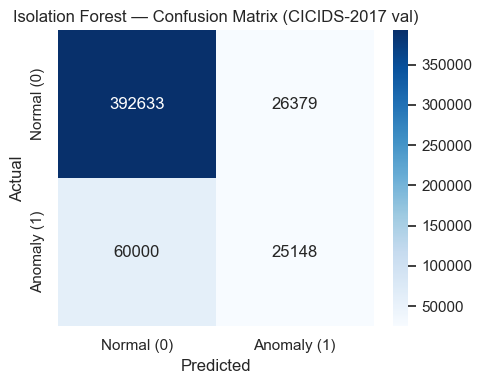

In [10]:
cm = confusion_matrix(y_true, prediction, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Normal (0)", "Anomaly (1)"],
    yticklabels=["Normal (0)", "Anomaly (1)"],
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Isolation Forest — Confusion Matrix (CICIDS-2017 val)")
plt.tight_layout()
plt.show()

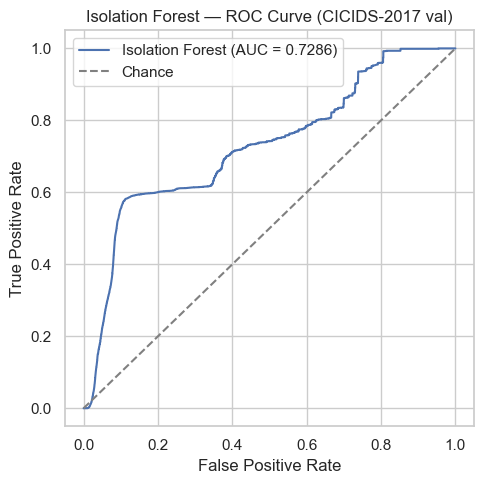

In [11]:
fpr_curve, tpr_curve, _ = roc_curve(y_true, anomaly_score)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr_curve, tpr_curve, label=f"Isolation Forest (AUC = {auc_roc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Isolation Forest — ROC Curve (CICIDS-2017 val)")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
val_scored = val_df.copy()
val_scored["_prediction"] = prediction
val_scored["_anomaly_score"] = anomaly_score

category_recall = (
    val_scored[val_scored["Label"] != "BENIGN"]
    .groupby("Label")["_prediction"]
    .agg(recall="mean", n_rows="size")
    .sort_values("recall")
)
category_recall

,recall,n_rows
Label,,
FTP-Patator,0.000000,1186
SSH-Patator,0.000000,644
Web Attack - Sql Injection,0.000000,4
Web Attack - XSS,0.000000,131
PortScan,0.001158,18139
Bot,0.023136,389
Web Attack - Brute Force,0.054422,294
DoS GoldenEye,0.198833,2057
DoS Slowhttptest,0.244976,1045


### 5b. Contamination tuning

AUC-ROC (0.7286, corrected 80-feature run) is noticeably higher than Precision/Recall/F1 —
the continuous anomaly score ranks attacks reasonably well, but `contamination='auto'` may
be setting the decision threshold too conservatively. Checked concretely below: what
threshold did `'auto'` actually resolve to, what's the real attack ratio in this validation
set, and does an explicit contamination value closer to that ratio give a better F1.

In [13]:
print(f"contamination='auto' resolved to offset_ = {iso_forest_main.offset_!r}")
print("sklearn hardcodes offset_ = -0.5 for contamination='auto' -- a fixed constant, not")
print("derived from this data at all, which is exactly why it can end up mismatched with")
print("the real anomaly rate.")

actual_attack_ratio = float((val_df["Label"] != "BENIGN").mean())
n_attack = int((val_df["Label"] != "BENIGN").sum())
print(f"\nActual attack ratio in cicids2017_features_val.parquet: {actual_attack_ratio:.4f} "
      f"({n_attack:,} attack rows / {len(val_df):,} total)")

contamination='auto' resolved to offset_ = -0.5
sklearn hardcodes offset_ = -0.5 for contamination='auto' -- a fixed constant, not
derived from this data at all, which is exactly why it can end up mismatched with
the real anomaly rate.

Actual attack ratio in cicids2017_features_val.parquet: 0.1689 (85,148 attack rows / 504,160 total)


In [14]:
CONTAMINATION_SWEEP = [0.05, 0.10, 0.15, 0.20]

sweep_rows = [{
    "contamination": "auto",
    "offset_": iso_forest_main.offset_,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "auc_roc": auc_roc,
}]

for c in CONTAMINATION_SWEEP:
    m = IsolationForest(n_estimators=N_ESTIMATORS, contamination=c, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train)
    pred_c = (m.predict(X_val) == -1).astype(int)
    score_c = -m.score_samples(X_val)
    sweep_rows.append({
        "contamination": c,
        "offset_": m.offset_,
        "precision": precision_score(y_true, pred_c),
        "recall": recall_score(y_true, pred_c),
        "f1": f1_score(y_true, pred_c),
        "auc_roc": roc_auc_score(y_true, score_c),
    })

contamination_sweep_df = pd.DataFrame(sweep_rows)

assert np.allclose(contamination_sweep_df["auc_roc"], contamination_sweep_df["auc_roc"].iloc[0], atol=1e-9), \
    "AUC-ROC should be identical across contamination values -- same ranking, only the cutoff differs"
print("Confirmed: AUC-ROC is identical across all contamination values (threshold-independent).\n")

contamination_sweep_df

Confirmed: AUC-ROC is identical across all contamination values (threshold-independent).



,contamination,offset_,precision,recall,f1,auc_roc
0,auto,-0.500000,0.488055,0.295345,0.367997,0.728624
1,0.05,-0.547342,0.336526,0.076338,0.124446,0.728624
2,0.1,-0.511460,0.480354,0.249530,0.328443,0.728624
3,0.15,-0.478481,0.518128,0.430662,0.470363,0.728624
4,0.2,-0.454789,0.529191,0.555785,0.542162,0.728624


In [15]:
best_idx = contamination_sweep_df["f1"].idxmax()
CONTAMINATION = contamination_sweep_df.loc[best_idx, "contamination"]
print(f"Chosen contamination (best F1 on val): {CONTAMINATION!r}  "
      f"(F1 = {contamination_sweep_df.loc[best_idx, 'f1']:.4f})")

iso_forest_main = IsolationForest(
    n_estimators=N_ESTIMATORS,
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
iso_forest_main.fit(X_train)

raw_normality_score = iso_forest_main.score_samples(X_val)
anomaly_score = -raw_normality_score
raw_pred = iso_forest_main.predict(X_val)
prediction = (raw_pred == -1).astype(int)

precision = precision_score(y_true, prediction)
recall = recall_score(y_true, prediction)
f1 = f1_score(y_true, prediction)
auc_roc = roc_auc_score(y_true, anomaly_score)

print(f"\nRefit with contamination={CONTAMINATION!r} (offset_={iso_forest_main.offset_:.6f}):")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1        : {f1:.4f}")
print(f"AUC-ROC   : {auc_roc:.4f}")

Chosen contamination (best F1 on val): 0.2  (F1 = 0.5422)



Refit with contamination=0.2 (offset_=-0.454789):
Precision : 0.5292
Recall    : 0.5558
F1        : 0.5422
AUC-ROC   : 0.7286


### 5c. Per-category recall at the chosen contamination

Re-running the Section 5 per-category breakdown with the tuned threshold, to see whether
raising the flagged-anomaly rate recovers any of the previously near-invisible categories
(FTP-Patator, SSH-Patator, PortScan) or whether they're fundamentally unreachable by an
anomaly-score approach regardless of cutoff.

In [16]:
val_scored_tuned = val_df.copy()
val_scored_tuned["_prediction"] = prediction
val_scored_tuned["_anomaly_score"] = anomaly_score

category_recall_tuned = (
    val_scored_tuned[val_scored_tuned["Label"] != "BENIGN"]
    .groupby("Label")["_prediction"]
    .agg(recall="mean", n_rows="size")
    .sort_values("recall")
)
category_recall_tuned

,recall,n_rows
Label,,
FTP-Patator,0.000000,1186
SSH-Patator,0.000000,644
Web Attack - Sql Injection,0.000000,4
Web Attack - XSS,0.000000,131
PortScan,0.002371,18139
Bot,0.023136,389
Web Attack - Brute Force,0.054422,294
DoS GoldenEye,0.479339,2057
DDoS,0.573136,25603


## 6. Zero-day (LOAO) evaluation

`loao_{category}_train.parquet` / `loao_{category}_zeroday_test.parquet` come straight out
of `preprocess_pipeline.py`, **not** `feature_extractor.py` — they predate the MITRE join
and the CTI/scaling/sentinel-imputation steps. So the feature set here is the 78 raw,
unscaled CICFlowMeter network columns only (no CTI columns, since those don't exist in
these files). `select_feature_columns` from Section 2 is reused as-is — it naturally
adapts to whatever numeric columns are present.

Isolation Forest is a tree-based, threshold-split model, so it's invariant to
monotonic per-feature scaling — training on unscaled features here is not a
methodological inconsistency with the scaled main-model run above.

`Init_Win_bytes_forward`/`Init_Win_bytes_backward` still carry the `-1`→`NaN` sentinel
(not yet imputed at this stage of the pipeline). Each LOAO fold imputes with a
train-only median, mirroring the train-only-fit principle `feature_extractor.py` uses
for the main splits — fit on that fold's LOAO train set, applied to both train and its
zero-day test set.

**Unaffected by the Section 2 leakage fix.** These LOAO parquet files come from
`preprocess_pipeline.py`, predating the MITRE join entirely — `technique_id_encoded`,
`tactic_encoded`, `mapping_confidence_encoded`, and `is_known_technique` never existed in
this data to begin with, so `select_feature_columns` was already excluding them by
construction (there was nothing to leak here) both before and after the fix. The LOAO
results in this section are identical to the first run.

**Uses the tuned `CONTAMINATION` value from Section 5b**, reassigned there (no longer
`'auto'`) -- each LOAO fold below refits its own `IsolationForest` with that same value, via
the existing `contamination=CONTAMINATION` reference in the loop below.

In [17]:
CATEGORIES = [
    ("DoS Hulk", "dos_hulk"),
    ("PortScan", "portscan"),
    ("DDoS", "ddos"),
    ("DoS GoldenEye", "dos_goldeneye"),
    ("FTP-Patator", "ftp_patator"),
    ("SSH-Patator", "ssh_patator"),
    ("DoS slowloris", "dos_slowloris"),
    ("DoS Slowhttptest", "dos_slowhttptest"),
    ("Bot", "bot"),
    ("Web Attack - Brute Force", "web_attack_brute_force"),
]

SENTINEL_COLS_LOAO = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]


def impute_sentinels_train_only(train_df_fold, test_df_fold, sentinel_cols):
    train_df_fold = train_df_fold.copy()
    test_df_fold = test_df_fold.copy()
    for c in sentinel_cols:
        median = train_df_fold[c].median(skipna=True)
        train_df_fold[c] = train_df_fold[c].fillna(median)
        test_df_fold[c] = test_df_fold[c].fillna(median)
    return train_df_fold, test_df_fold

In [18]:
loao_results = []

for display_name, slug in CATEGORIES:
    loao_train_df = pd.read_parquet(LOAO_DIR / f"loao_{slug}_train.parquet")
    loao_test_df = pd.read_parquet(LOAO_DIR / f"loao_{slug}_zeroday_test.parquet")

    loao_train_df, loao_test_df = impute_sentinels_train_only(loao_train_df, loao_test_df, SENTINEL_COLS_LOAO)

    loao_feature_cols = select_feature_columns(loao_train_df)
    X_loao_train = loao_train_df[loao_feature_cols].to_numpy(dtype=np.float64)
    X_loao_test = loao_test_df[loao_feature_cols].to_numpy(dtype=np.float64)

    loao_model = IsolationForest(
        n_estimators=N_ESTIMATORS,
        contamination=CONTAMINATION,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    loao_model.fit(X_loao_train)

    loao_pred = (loao_model.predict(X_loao_test) == -1).astype(int)
    loao_y_true = (loao_test_df["Label"] != "BENIGN").astype(int).to_numpy()

    tp = int(((loao_pred == 1) & (loao_y_true == 1)).sum())
    fn = int(((loao_pred == 0) & (loao_y_true == 1)).sum())
    fp = int(((loao_pred == 1) & (loao_y_true == 0)).sum())
    tn = int(((loao_pred == 0) & (loao_y_true == 0)).sum())

    fold_recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    fold_fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")

    loao_results.append({
        "category": display_name,
        "recall": fold_recall,
        "fpr": fold_fpr,
        "n_test_rows": len(loao_test_df),
        "n_attack_rows": int(loao_y_true.sum()),
        "n_benign_rows": int((loao_y_true == 0).sum()),
    })

    print(f"{display_name:30s}  recall={fold_recall:.4f}  fpr={fold_fpr:.4f}  n_test={len(loao_test_df)}")

loao_summary_df = pd.DataFrame(loao_results).sort_values("recall").reset_index(drop=True)

DoS Hulk                        recall=0.9004  fpr=0.1694  n_test=591858


PortScan                        recall=0.0020  fpr=0.1096  n_test=509706


DDoS                            recall=0.6348  fpr=0.1323  n_test=547026


DoS GoldenEye                   recall=0.7298  fpr=0.1170  n_test=429298


FTP-Patator                     recall=0.0008  fpr=0.1158  n_test=424943


SSH-Patator                     recall=0.0034  fpr=0.1218  n_test=422231


DoS slowloris                   recall=0.6132  fpr=0.1176  n_test=424397


DoS Slowhttptest                recall=0.8470  fpr=0.1194  n_test=424240


Bot                             recall=0.0231  fpr=0.1216  n_test=420960


Web Attack - Brute Force        recall=0.0503  fpr=0.1207  n_test=420482


In [19]:
loao_summary_df

,category,recall,fpr,n_test_rows,n_attack_rows,n_benign_rows
0,FTP-Patator,0.000843,0.115789,424943,5931,419012
1,PortScan,0.002018,0.109562,509706,90694,419012
2,SSH-Patator,0.003417,0.121839,422231,3219,419012
3,Bot,0.023101,0.121629,420960,1948,419012
4,Web Attack - Brute Force,0.050340,0.120734,420482,1470,419012
5,DoS slowloris,0.613185,0.117608,424397,5385,419012
6,DDoS,0.634806,0.132316,547026,128014,419012
7,DoS GoldenEye,0.729827,0.117001,429298,10286,419012
8,DoS Slowhttptest,0.846978,0.119419,424240,5228,419012
9,DoS Hulk,0.900414,0.169387,591858,172846,419012


## 7. Save the model + results

In [20]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODELS_DIR / "isolation_forest.pkl"
joblib.dump(iso_forest_main, model_path)
print("Saved main model to", model_path)

Saved main model to E:\thesis\models\isolation_forest.pkl


In [21]:
sweep_path = REPORTS_DIR / "isolation_forest_contamination_sweep.csv"
contamination_sweep_df.to_csv(sweep_path, index=False)
print("Saved contamination sweep table to", sweep_path)

Saved contamination sweep table to E:\thesis\reports\isolation_forest_contamination_sweep.csv


In [22]:
OLD_LOAO_RESULTS_AUTO_CONTAMINATION = [
    {"category": "FTP-Patator", "recall": 0.0, "fpr": 0.06124168281576661, "n_test_rows": 424943, "n_attack_rows": 5931, "n_benign_rows": 419012},
    {"category": "SSH-Patator", "recall": 0.0, "fpr": 0.06198151842906647, "n_test_rows": 422231, "n_attack_rows": 3219, "n_benign_rows": 419012},
    {"category": "PortScan", "recall": 0.0012569740004851478, "fpr": 0.0643776311895602, "n_test_rows": 509706, "n_attack_rows": 90694, "n_benign_rows": 419012},
    {"category": "Bot", "recall": 0.022587268993839837, "fpr": 0.06304354051912595, "n_test_rows": 420960, "n_attack_rows": 1948, "n_benign_rows": 419012},
    {"category": "Web Attack - Brute Force", "recall": 0.04897959183673469, "fpr": 0.06453753114469275, "n_test_rows": 420482, "n_attack_rows": 1470, "n_benign_rows": 419012},
    {"category": "DoS GoldenEye", "recall": 0.21174411821893838, "fpr": 0.062220175078518035, "n_test_rows": 429298, "n_attack_rows": 10286, "n_benign_rows": 419012},
    {"category": "DDoS", "recall": 0.39546455856390705, "fpr": 0.06606254713468826, "n_test_rows": 547026, "n_attack_rows": 128014, "n_benign_rows": 419012},
    {"category": "DoS slowloris", "recall": 0.5706592386258125, "fpr": 0.06252565558981604, "n_test_rows": 424397, "n_attack_rows": 5385, "n_benign_rows": 419012},
    {"category": "DoS Slowhttptest", "recall": 0.7939938791124713, "fpr": 0.062215401945529006, "n_test_rows": 424240, "n_attack_rows": 5228, "n_benign_rows": 419012},
    {"category": "DoS Hulk", "recall": 0.8196602756210731, "fpr": 0.06852309719053393, "n_test_rows": 591858, "n_attack_rows": 172846, "n_benign_rows": 419012},
]
old_loao_df = pd.DataFrame(OLD_LOAO_RESULTS_AUTO_CONTAMINATION)
old_loao_df["status"] = "superseded_auto_contamination"

new_loao_df = loao_summary_df.copy()
new_loao_df["status"] = "current_contamination_tuned"

loao_csv_path = REPORTS_DIR / "isolation_forest_loao_results.csv"
combined_loao_df = pd.concat([old_loao_df, new_loao_df], ignore_index=True)
combined_loao_df.to_csv(loao_csv_path, index=False)
print("Saved LOAO summary (auto-contamination [superseded] + tuned [current]) to", loao_csv_path)
combined_loao_df

Saved LOAO summary (auto-contamination [superseded] + tuned [current]) to E:\thesis\reports\isolation_forest_loao_results.csv


,category,recall,fpr,n_test_rows,n_attack_rows,n_benign_rows,status
0,FTP-Patator,0.000000,0.061242,424943,5931,419012,superseded_auto_contamination
1,SSH-Patator,0.000000,0.061982,422231,3219,419012,superseded_auto_contamination
2,PortScan,0.001257,0.064378,509706,90694,419012,superseded_auto_contamination
3,Bot,0.022587,0.063044,420960,1948,419012,superseded_auto_contamination
4,Web Attack - Brute Force,0.048980,0.064538,420482,1470,419012,superseded_auto_contamination
5,DoS GoldenEye,0.211744,0.062220,429298,10286,419012,superseded_auto_contamination
6,DDoS,0.395465,0.066063,547026,128014,419012,superseded_auto_contamination
7,DoS slowloris,0.570659,0.062526,424397,5385,419012,superseded_auto_contamination
8,DoS Slowhttptest,0.793994,0.062215,424240,5228,419012,superseded_auto_contamination
9,DoS Hulk,0.819660,0.068523,591858,172846,419012,superseded_auto_contamination


In [23]:
CORRECTED_METRICS["status"] = "superseded_auto_contamination"

TUNED_METRICS = {
    "status": "current_contamination_tuned",
    "n_features": len(feature_cols),
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "auc_roc": auc_roc,
}

val_metrics_comparison_df = pd.DataFrame([PRE_FIX_METRICS, CORRECTED_METRICS, TUNED_METRICS])
val_metrics_path = REPORTS_DIR / "isolation_forest_val_metrics.csv"
val_metrics_comparison_df.to_csv(val_metrics_path, index=False)
print("Saved val-set metrics comparison (pre-leakage-fix / auto-contamination / tuned) to", val_metrics_path)
val_metrics_comparison_df

Saved val-set metrics comparison (pre-leakage-fix / auto-contamination / tuned) to E:\thesis\reports\isolation_forest_val_metrics.csv


,status,n_features,precision,recall,f1,auc_roc
0,superseded_pre_leakage_fix,84,0.520700,0.298100,0.379200,0.854900
1,superseded_auto_contamination,80,0.488055,0.295345,0.367997,0.728624
2,current_contamination_tuned,80,0.529191,0.555785,0.542162,0.728624


In [24]:
val_scores_df = pd.DataFrame({
    "row_index": val_df.index.to_numpy(),
    "anomaly_score": anomaly_score,
    "prediction": prediction,
})

val_scores_path = DATA_FEATURES_DIR / "cicids2017_isoforest_scores_val.parquet"
val_scores_df.to_parquet(val_scores_path, index=False)
print("Saved val-set scores to", val_scores_path)
val_scores_df.head()

Saved val-set scores to E:\thesis\data\features\cicids2017_isoforest_scores_val.parquet


,row_index,anomaly_score,prediction
0,0,0.469091,1
1,1,0.644691,1
2,2,0.348013,0
3,3,0.332281,0
4,4,0.335812,0
